# Detección y explicación de pérdidas de tiempo en karting a partir de telemetría

Alumno: Luciano Perissutti



## 1. Identificación del problema

### Contexto
En el karting de competición, la diferencia entre una vuelta buena y una mala suele ser de unas pocas décimas de segundo, que se pierden de a poco en cada curva. Los karts registran telemetría (velocidad, aceleraciones, posición GPS, RPM), pero para el piloto no es fácil traducir esos datos en una respuesta concreta del qué esta haciendo mal.

Normalmente ese análisis se hace a mano, comparando vueltas en un software, o con reglas fijas definidas por un experto. En este trabajo se busca que un modelo aprenda de los datos qué diferencia una pasada por curva buena de una mala.

### Objetivo
Construir un modelo de Machine Learning que, a partir de cómo el piloto toma cada curva (frenada, reaceleración, velocidad de entrada), identifique las pasadas en las que pierde tiempo y permita explicar qué factor lo causa. A partir de esas explicaciones se busca determinar el factor de pérdida que más se repite en cada tanda.

### Preguntas a responder
1. ¿Las acciones del piloto en una curva permiten predecir si esa pasada pierde tiempo frente a su referencia?
2. ¿Qué factores explican en mayor medida la pérdida de tiempo?
3. Dada una tanda nueva, no vista por el modelo, ¿cuál es el factor de pérdida que más se repite?

### Tipo de problema
- Aprendizaje supervisado, clasificación binaria. Cada pasada por curva se etiqueta como "pierde tiempo" (1) o "no pierde tiempo" (0), según si su pérdida contra la referencia del piloto (el promedio de sus 3 mejores pasadas en esa curva) supera la mediana de esa curva.
 La etiqueta se obtiene del cronometraje, por lo que no se requiere un etiquetado manual.
- Unidad de análisis: una pasada, es decir, una curva en una vuelta.
- Modelo principal: Random Forest, comparado contra modelos de referencia más simples.
- Explicación: importancia de variables a nivel global, y comparación entre las pasadas buenas y malas de cada tanda para obtener el patrón más relevante.

### Alcance
- Datos reales de 21 tandas registradas con MyChron (GPS a 20 Hz) en el circuito de Villaguay, Entre Ríos (14 al 16 de agosto de 2026), de 3 pilotos anonimizados (P1, P2, P3).
- Se trabaja solo con tandas con pista en seco. Las tandas con pista en mojado se identifican en el análisis exploratorio y se excluyen del entrenamiento.
- Se cuenta con canales como: velocidad, aceleraciones, posición GPS, RPM y marcha. No hay sensores de freno ni de acelerador, por lo que la frenada y la reaceleración se infieren a partir de la aceleración longitudinal.

### Utilidad esperada
Un modelo que funcione permitiría darle al piloto un diagnóstico automático y concreto de cada tanda (por ejemplo, "el factor que más se repite es llegar lento a la curva y hacer el vértice temprano, principalmente en la curva 8"), y sirve también para evaluar si un enfoque de aprendizaje automático aporta información adicional frente al análisis basado en reglas.

## 2. Obtención de los datos y construcción del dataset

###Fuente de datos
Los datos provienen de 21 tandas reales registradas con dataloggers AiM MyChron en el circuito de Villaguay, Entre Ríos, entre el 14 y el 16 de agosto de 2026, correspondientes a 3 pilotos (anonimizados como P1, P2 y P3). Los archivos se exportaron desde Race Studio 3 en formato CSV.

Cada archivo contiene una serie temporal a 20 Hz con los siguientes canales relevantes:
- velocidad GPS
- aceleración lateral y longitudinal (g)
- posición GPS (latitud y longitud)
- distancia recorrida (calculada a partir de la velocidad)
- RPM

Además, el encabezado de cada archivo incluye los tiempos de vuelta marcados por la baliza (beacon) de meta.

No se dispone de sensores de freno ni de acelerador.

###Unidad de análisis: la pasada
La vuelta (aproximadamente 1.255 m) se divide en 13 tramos, uno por curva. Cada tramo va desde el punto medio entre la curva anterior y esa curva, hasta el punto medio con la curva siguiente. De esta forma, la suma de los 13 tramos equivale a la vuelta completa.

Cada pasada (una curva en una vuelta) es una fila del dataset.

###Construcción de la variable objetivo
Para cada pasada se calcula:
- `tiempo_tramo`: tiempo empleado en el tramo, interpolado entre muestras para mayor precisión.
- `referencia`: promedio de las 3 mejores pasadas del mismo piloto en ese tramo, considerando todas sus tandas en seco.
- `perdida_ms`= `tiempo_tramo` - `referencia`.
- `pierde` (objetivo): 1 si `perdida_ms` es mayor que la mediana de pérdida de esa curva, 0 en caso contrario (ver justificación en el EDA).

La referencia se calcula por piloto para que el modelo aprenda errores de manejo y no diferencias de nivel entre pilotos.

###Variables de entrada (ingeniería de características)
A partir de las series crudas se calculan variables que describen cómo el piloto tomó la curva, expresadas como diferencia respecto de su referencia:

Variable y Descripción:

- `d_frenada` -> Diferencia en el punto de inicio de frenada (m). Positivo = frenó antes

- `g_frenada` -> Diferencia en la desaceleración máxima (g)
- `dur_frenada` -> Diferencia en la duración de la frenada (s)
- `hay_frenada` -> Indica si hubo frenada en esa curva (0/1)
- `d_vertice` -> Diferencia en la posición del punto de menor velocidad (m)
- `d_reaceleracion` -> Diferencia en el punto donde vuelve a acelerar (m)
- `g_lateral` -> Diferencia en la aceleración lateral máxima (g)
- `v_entrada` -> Diferencia en la velocidad al inicio del tramo (km/h)
- `nro_vuelta` -> Número de vuelta dentro de la tanda

Las posiciones se miden sobre la distancia recorrida, que se calcula a partir de la velocidad, y no a partir de la posición GPS.

###Variables excluidas
- Velocidad mínima, velocidad de salida y tiempo del tramo: son consecuencia de la pasada (el resultado), no una acción del piloto. Incluirlas produciría fuga de información.
- Trayectoria (desvío lateral): el GPS de uno de los pilotos presenta un error de posición de aproximadamente 2 metros, mayor que las diferencias de trayectoria que se quieren medir.
- Marcha: el canal no está calibrado en uno de los equipos.
- RPM mínimas: aportan la misma informacion que la velocidad mínima.
- Piloto y tanda: se usan solo para calcular la referencia y para dividir los datos. No son variables del modelo.

###Tamaño esperado
Tras excluir las tandas en mojado (ver EDA) quedan 17 tandas en seco y 73 vueltas válidas, es decir, aproximadamente 949 pasadas (73 * 13).

Los 21 archivos de telemetría se procesaron con un script en Python que corta cada tanda en vueltas y mide, para cada una de las 13 curvas, el tiempo del tramo, la velocidad de entrada, el vértice, la frenada, la reaceleración y la aceleración lateral. El resultado es el archivo `pasadas_villaguay.csv`, con una fila por pasada. Que va a ser el archivo que utilice el modelo de ML.

In [ ]:
# Importación de las librerías necesarias para todo el trabajo
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import GridSearchCV, GroupKFold

In [ ]:
#Cargamos y leemos el archivo del dataset
datos = pd.read_csv("pasadas_villaguay.csv")

print("Dimensiones:", datos.shape)
print("Tandas:", datos.tanda.nunique(), ", Pilotos:", sorted(datos.piloto.unique())) #Comprobar cuantas tandas y que pilotos hay
datos.head()

Dimensiones: (1261, 16)
Tandas: 21 , Pilotos: ['P1', 'P2', 'P3']


,piloto,tanda,vuelta,tiempo_vuelta,g_lat_max_vuelta,curva,tiempo_tramo,vel_entrada,pos_vertice,vel_min,g_lat_curva,hay_frenada,pos_frenada,g_frenada_max,duracion_frenada,pos_reaceleracion
0,P1,T01,1,63.227,1.545,1,10.395,90.512,211.528,67.865,1.549,1,148.790,-0.358,0.25,217.206
1,P1,T01,1,63.227,1.545,2,5.005,74.185,261.808,72.527,1.514,0,NaN,0.000,0.00,290.382
2,P1,T01,1,63.227,1.545,3,3.690,79.808,376.353,52.395,1.450,1,339.717,-0.805,1.00,377.805
3,P1,T01,1,63.227,1.545,4,1.957,59.489,401.395,60.937,0.997,0,NaN,0.000,0.00,401.395
4,P1,T01,1,63.227,1.545,5,1.430,69.726,447.948,73.566,0.696,0,NaN,0.000,0.00,447.948


## 3. Preprocesamiento y análisis exploratorio (EDA)

###Detección de vueltas en mojado
No se registró el estado de la pista. Se analiza la aceleración lateral máxima de cada vuelta: en mojado hay menos agarre, por lo que debería ser menor.

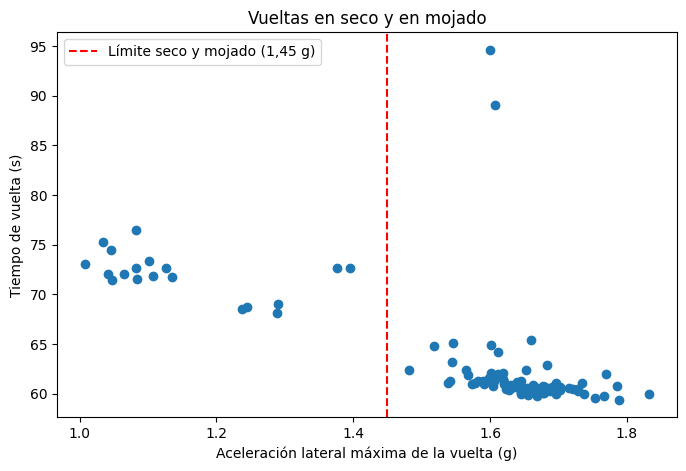

Vueltas completas: 97
Vueltas en mojado: 19


In [ ]:
vueltas = datos.drop_duplicates(["tanda", "vuelta"]) #1 fila por vuelta, los datos se repiten en sus 13 curvas

plt.figure(figsize=(8, 5))
plt.scatter(vueltas.g_lat_max_vuelta, vueltas.tiempo_vuelta)
plt.axvline(1.45, color="red", linestyle="--", label="Límite seco y mojado (1,45 g)")
plt.xlabel("Aceleración lateral máxima de la vuelta (g)")
plt.ylabel("Tiempo de vuelta (s)")
plt.title("Vueltas en seco y en mojado")
plt.legend()
plt.show()

print("Vueltas completas:", len(vueltas)) #Total de vueltas
print("Vueltas en mojado:", (vueltas.g_lat_max_vuelta < 1.45).sum()) #Vueltas por debajo del limite

Se observan dos grupos bien separados: las vueltas en seco (1,5 a 1,8 g, entre 59 y 65 s) y las vueltas en mojado (1,0 a 1,4 g, entre 68 y 76 s). Se identifican 19 vueltas en mojado, que se excluyen porque el comportamiento del kart es distinto y el modelo aprendería a distinguir mojado de seco en lugar de errores de manejo.

También aparecen dos vueltas de 89 y 95 s en seco: son vueltas de entrada a boxes, que se eliminan con el filtro siguiente.

###Filtrado de vueltas
Se conservan solo las vueltas en seco y las vueltas "rápidas", definidas como aquellas que no superan en más de un 7 % a la mejor vuelta de su tanda.

In [ ]:
datos = datos[datos.g_lat_max_vuelta >= 1.45] #Solo guardamos las vueltas en pista seca

mejor_vuelta = datos.groupby("tanda").tiempo_vuelta.transform("min") #Guardamos la mejor vuelta de cada tanda, repetida en cada fila de esa tanda
datos = datos[datos.tiempo_vuelta <= mejor_vuelta * 1.07] #Descartamos las vueltas que son mas de un 7% mas lenta (errores, boxes, etc)

print("Tandas:", datos.tanda.nunique())
print("Vueltas:", len(datos.drop_duplicates(["tanda", "vuelta"])))
print("Pasadas:", len(datos))

Tandas: 17
Vueltas: 73
Pasadas: 949


###Referencia de cada piloto
Para cada piloto y cada curva se toma como referencia el promedio de sus 3 mejores pasadas (las de menor tiempo de tramo). Se usa el promedio de 3 y no la mejor sola para que una pasada aislada no defina la referencia.

In [ ]:
mejores = datos.sort_values("tiempo_tramo").groupby(["piloto", "curva"]).head(3) #Las 3 pasadas mas rapidas de cada piloto en cada curva

#Promedio de esas 3 pasadas, es la referencia del piloto en esa curva
referencia = mejores.groupby(["piloto", "curva"])[["tiempo_tramo", "vel_entrada", "pos_vertice", "g_lat_curva",
                "pos_frenada", "g_frenada_max", "duracion_frenada", "pos_reaceleracion"]].mean()
referencia = referencia.add_suffix("_ref").reset_index() #Le agregamos una referencia al nombre de cada columna

datos = datos.merge(referencia, on=["piloto", "curva"]) #Le pasamos a cada pasada la referencia de su piloto y curva
referencia[referencia.piloto == "P3"] #Referencia de P3

,piloto,curva,tiempo_tramo_ref,vel_entrada_ref,pos_vertice_ref,g_lat_curva_ref,pos_frenada_ref,g_frenada_max_ref,duracion_frenada_ref,pos_reaceleracion_ref
26,P3,1,9.480333,95.400667,217.433333,1.710000,126.768667,-0.419333,0.333333,224.444000
27,P3,2,4.735667,77.380667,270.091333,1.653667,NaN,0.000000,0.000000,300.719333
28,P3,3,3.328333,83.851333,375.286000,1.560000,346.184333,-0.810333,1.150000,386.003000
29,P3,4,1.898333,62.021667,402.089333,1.090667,NaN,0.000000,0.000000,405.317333
30,P3,5,1.370333,72.099000,447.705667,0.969000,NaN,0.000000,0.000000,447.705667
31,P3,6,3.384333,78.105667,496.455333,1.675667,NaN,0.000000,0.000000,512.607667
32,P3,7,5.248000,80.939333,601.861000,1.681000,554.935333,-0.636000,0.666667,613.486333
33,P3,8,2.953000,72.898667,644.609667,1.319667,NaN,0.000000,0.000000,644.609667
34,P3,9,4.033667,81.103000,758.419000,1.639333,722.112000,-0.742000,1.200000,764.192333
35,P3,10,4.522000,58.823667,802.894000,1.650333,782.682500,-0.259333,0.150000,806.336000


###Variables como diferencia contra la referencia
Cada variable se expresa como la diferencia entre la pasada y la referencia del piloto en esa curva. Así se pueden comparar pilotos y curvas distintas. En las curvas sin frenada, las diferencias de frenada valen 0.

In [ ]:
datos["d_frenada"] = (datos.pos_frenada_ref - datos.pos_frenada).fillna(0)     # + = frenó antes (0 si no hay frenada)
datos["g_frenada"] = datos.g_frenada_max_ref - datos.g_frenada_max             # + = frenó más fuerte
datos["dur_frenada"] = datos.duracion_frenada - datos.duracion_frenada_ref     # + = frenada más larga
datos["d_vertice"] = datos.pos_vertice - datos.pos_vertice_ref                 # + = vértice más tarde
datos["d_reaceleracion"] = (datos.pos_reaceleracion - datos.pos_reaceleracion_ref).fillna(0)  # + = aceleró más tarde
datos["g_lateral"] = datos.g_lat_curva - datos.g_lat_curva_ref                 # − = usó menos agarre
datos["v_entrada"] = datos.vel_entrada - datos.vel_entrada_ref                 # − = llegó más lento
datos["nro_vuelta"] = datos.vuelta

datos["perdida_ms"] = (datos.tiempo_tramo - datos.tiempo_tramo_ref) * 1000 #Tiempo perdido en ms contra la referencia
datos.perdida_ms.describe()

,perdida_ms
count,949.000000
mean,117.825430
std,143.759786
min,-63.666667
25%,32.333333
50%,84.666667
75%,159.000000
max,1886.666667


###Definición de la variable objetivo
Se analiza la distribución de la pérdida para elegir el umbral de `pierde`.

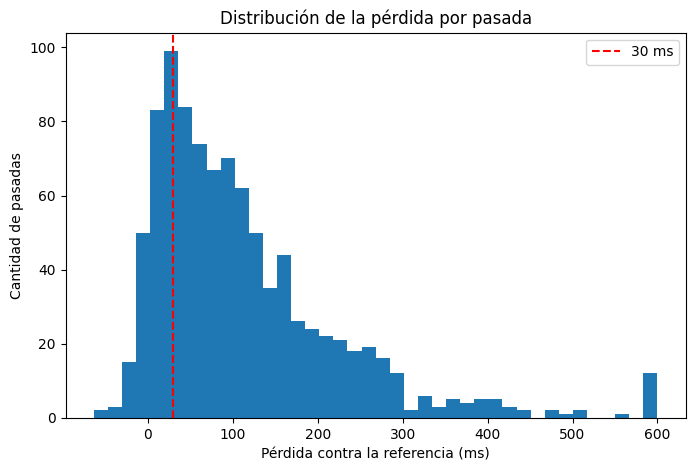

Pasadas con más de 30 ms de pérdida: 77 %


In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(datos.perdida_ms.clip(upper=600), bins=40)
plt.axvline(30, color="red", linestyle="--", label="30 ms")
plt.xlabel("Pérdida contra la referencia (ms)")
plt.ylabel("Cantidad de pasadas")
plt.title("Distribución de la pérdida por pasada")
plt.legend()
plt.show()

print("Pasadas con más de 30 ms de pérdida:", round((datos.perdida_ms > 30).mean() * 100), "%")

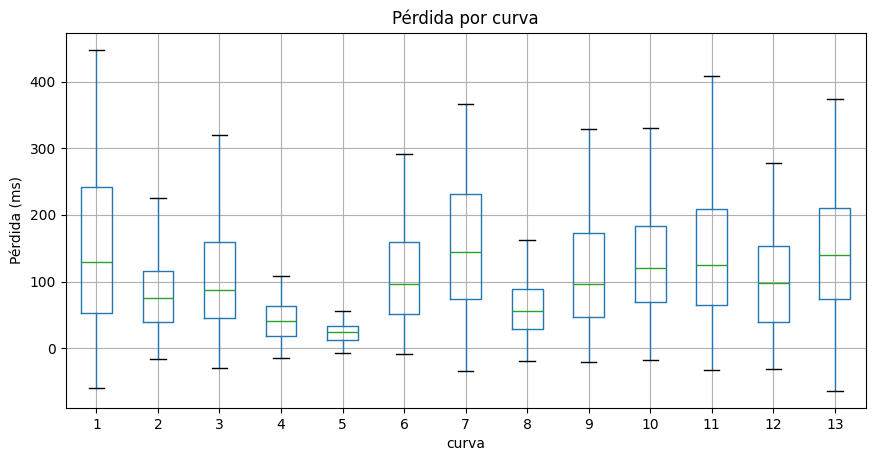

In [ ]:
datos.boxplot(column="perdida_ms", by="curva", figsize=(10, 5), showfliers=False)
plt.ylabel("Pérdida (ms)")
plt.title("Pérdida por curva")
plt.suptitle("")
plt.show()

Con el umbral inicial de 30 ms, el 77 % de las pasadas quedaría como "pierde": como la referencia es el promedio de las 3 mejores pasadas, casi todas las demás quedan por encima. Además, la pérdida típica cambia mucho según la curva: en las curvas 4 y 5 (tramos cortos) es de 20 a 40 ms, y en las curvas 1, 7 y 13 (tramos largos) supera los 120 ms.

Por eso se define `pierde` = 1 si la pérdida es mayor que la mediana de esa curva. Así cada curva se compara contra sí misma y las clases quedan balanceadas.


In [ ]:
mediana_curva = datos.groupby("curva").perdida_ms.transform("median") #Mediana de la perdida de cada curva, repetida en cada fila
datos["pierde"] = (datos.perdida_ms > mediana_curva).astype(int) #1 = la pasada esta en la mitad mas lenta de la curva, 0 = no lo esta

datos.pierde.value_counts()

,count
pierde,
0,484
1,465


###Relación de las variables con la pérdida

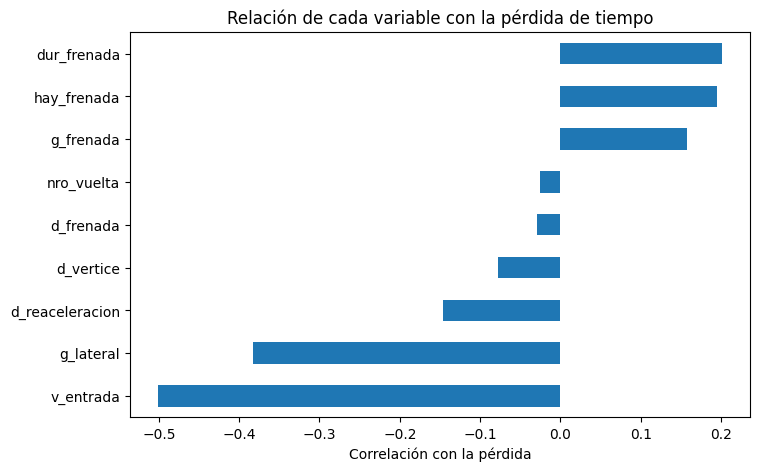

In [ ]:
variables = ["d_frenada", "g_frenada", "dur_frenada", "hay_frenada", "d_vertice",
             "d_reaceleracion", "g_lateral", "v_entrada", "nro_vuelta"] #9 variables de entrada

correlacion = datos[variables + ["perdida_ms"]].corr()["perdida_ms"].drop("perdida_ms").sort_values() #Correlacion de cada variable con la perdida
correlacion.plot(kind="barh", figsize=(8, 5))
plt.xlabel("Correlación con la pérdida")
plt.title("Relación de cada variable con la pérdida de tiempo")
plt.show()

Las variables más relacionadas con la pérdida son:
- `v_entrada` (-0,50): llegar más lento a la curva, por una mala salida de la curva anterior, es lo que más se asocia a perder tiempo.
- `g_lateral` (-0,37): usar menos agarre lateral que en las mejores pasadas se asocia a perder tiempo.
- Frenada (`dur_frenada`, `hay_frenada`, `g_frenada`, entre 0,15 y 0,20): frenadas más largas y más fuertes también suman pérdida.

El punto de frenada (`d_frenada`) casi no tiene correlación lineal, pero puede tener efecto en combinación con otras variables. Eso lo evalúa el modelo en las secciones siguientes.

## 4. Selección de modelos y justificación

Se trata de un problema de clasificación binaria (`pierde` = 0 o 1) con 9 variables numéricas. Se comparan modelos basados en árboles de decisión, vistos en la materia:

- Árbol de decisión (Gini): modelo simple e interpretable, sirve como punto de partida.
- Árbol de decisión con poda (`ccp_alpha`): limita el crecimiento del árbol para reducir el overfitting.
- Random Forest: combina muchos árboles entrenados en paralelo sobre muestras distintas de los datos. Es robusto con pocos datos y permite medir la importancia de cada variable.
- Gradient Boosting: combina árboles en secuencia, donde cada uno corrige los errores del anterior.

Se eligen modelos de árboles porque:
1. No requieren escalar las variables.
2. Capturan relaciones no lineales y combinaciones entre variables (por ejemplo, el punto de frenada puede importar solo cuando la velocidad de entrada es baja).
3. Permiten obtener la importancia de cada variable, necesaria para responder qué factor explica la pérdida de tiempo.

## 5. Entrenamiento y validación

###División del dataset
No se usa `train_test_split` al azar, porque las pasadas de una misma tanda se parecen mucho entre sí (mismas gomas, temperatura y ritmo del piloto). Si una vuelta de una tanda queda en entrenamiento y otra de la misma tanda en testeo, el modelo se evalúa con datos casi vistos.

Por eso se separan tandas completas: las 4 tandas más recientes (al menos una de cada piloto) se usan para testeo y las 13 restantes para entrenamiento. Esto simula el uso real del modelo: entrenar con tandas pasadas y aplicarlo a tandas nuevas.

In [ ]:
variables = ["d_frenada", "g_frenada", "dur_frenada", "hay_frenada", "d_vertice",
             "d_reaceleracion", "g_lateral", "v_entrada", "nro_vuelta"]   # lo que el modelo mira para decidir

# Las 4 tandas más nuevas en seco, para probar el modelo (T20 no está porque era en mojado y ya la sacamos)
tandas_test = ["T17", "T18", "T19", "T21"]   # P2, P1, P3 y P1: están los 3 pilotos

train = datos[~datos.tanda.isin(tandas_test)]   # todas las filas que NO son de esas 4 tandas -> para entrenar
test = datos[datos.tanda.isin(tandas_test)]     # solo las filas de esas 4 tandas -> para testear

X_train, y_train = train[variables], train.pierde   # entrenamiento: variables (X) y respuesta correcta (y)
X_test, y_test = test[variables], test.pierde       # testeo: lo mismo, pero con tandas que el modelo nunca vio

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Tandas de testeo:", test.groupby("tanda").piloto.first().to_dict())   # qué piloto es cada tanda de testeo

X_train: (663, 9)
X_test: (286, 9)
Tandas de testeo: {'T17': 'P2', 'T18': 'P1', 'T19': 'P3', 'T21': 'P1'}


###Entrenamiento de los modelos

In [ ]:
#Se usa random_state = 42, para fijar el azar para que los resultados se repitan en cada ejecucion
modelArbol = DecisionTreeClassifier(criterion="gini", random_state=42) #Arbol sin limite de crecimiento
modelArbol.fit(X_train, y_train)

modelPoda = DecisionTreeClassifier(ccp_alpha=0.01, random_state=42) #arbol con poda, el parametro alpha poda las ramas que aportan poco para el performance
modelPoda.fit(X_train, y_train)

modelRF = RandomForestClassifier(n_estimators=100, random_state=42)#random forest con 100 arboles
modelRF.fit(X_train, y_train)

modelGB = GradientBoostingClassifier(n_estimators=100, random_state=42)#gradient boosting con 100 arboles
modelGB.fit(X_train, y_train)

GradientBoostingClassifier(random_state=42)

In [ ]:
predArbol = modelArbol.predict(X_test)
predPoda = modelPoda.predict(X_test)
predRF = modelRF.predict(X_test)
predGB = modelGB.predict(X_test)

print("Accuracy en entrenamiento y testeo:")
print("Árbol:            ", round(accuracy_score(y_train, modelArbol.predict(X_train)), 3), " y ", round(accuracy_score(y_test, predArbol), 3))
print("Árbol con poda:   ", round(accuracy_score(y_train, modelPoda.predict(X_train)), 3), " y ", round(accuracy_score(y_test, predPoda), 3))
print("Random Forest:    ", round(accuracy_score(y_train, modelRF.predict(X_train)), 3), " y ", round(accuracy_score(y_test, predRF), 3))
print("Gradient Boosting:", round(accuracy_score(y_train, modelGB.predict(X_train)), 3), " y ", round(accuracy_score(y_test, predGB), 3))

Accuracy en entrenamiento y testeo:
Árbol:             1.0  y  0.643
Árbol con poda:    0.725  y  0.65
Random Forest:     1.0  y  0.699
Gradient Boosting: 0.893  y  0.636


El árbol sin poda memoriza el entrenamiento (100 %) pero baja a 64 % en testeo: es un caso claro de overfitting. La poda reduce esa diferencia (72,5 % en entrenamiento contra 65 % en testeo) y mejora levemente el testeo.

El Random Forest obtiene el mejor resultado en testeo (70 %). Aunque también llega a 100 % en entrenamiento, al promediar 100 árboles distintos generaliza mejor que un árbol solo.

Gradient Boosting queda en 64 % con sus hiperparámetros por defecto.

Se elige Random Forest como modelo principal. Para comparar, una respuesta al azar acertaría alrededor del 50 %, ya que las clases están balanceadas en el total del dataset.

## 6. Evaluación del rendimiento y métricas

Además del accuracy, se analizan las métricas por clase, porque interesa especialmente cómo se comporta el modelo con las pasadas que pierden tiempo (clase 1):

- Precision (clase 1): de las pasadas que el modelo marcó como "pierde", cuántas realmente perdieron.
- Recall (clase 1): de las pasadas que realmente perdieron, cuántas detectó el modelo.
- F1-score: promedio entre precision y recall.

El objetivo es encontrar el error que más se repite, interesa sobre todo el recall: que el modelo no deje pasar las pasadas malas.

In [ ]:
print("Reporte de clasificación - Random Forest")
print(classification_report(y_test, predRF)) #metricas obtenidas

Reporte de clasificación - Random Forest
              precision    recall  f1-score   support

           0       0.76      0.72      0.74       169
           1       0.62      0.68      0.65       117

    accuracy                           0.70       286
   macro avg       0.69      0.70      0.69       286
weighted avg       0.70      0.70      0.70       286



In [ ]:
print("Matriz de confusión - Random Forest")
print(confusion_matrix(y_test, predRF))   # Matriz de confusion

Matriz de confusión - Random Forest
[[121  48]
 [ 38  79]]


Análisis de resultados

El Random Forest obtiene un accuracy de 70 % en las 4 tandas de testeo. De las 117 pasadas que realmente perdieron tiempo, detectó 79 (recall de 0,68, aproximadamente 2 de cada 3), y de las 127 que marcó como "pierde", 79 eran correctas (precision de 0,62).

En el testeo el 59 % de las pasadas son "no pierde", por lo que responder siempre eso daría 59 %, el modelo lo supera y además detecta 2 de cada 3 pasadas malas.

## 7. Ajuste de hiperparámetros y optimización

###Búsqueda de hiperparámetros
Se usa `GridSearchCV` para probar combinaciones de hiperparámetros del Random Forest:
- `n_estimators`: cantidad de árboles.
- `max_depth`: profundidad máxima de cada árbol (limita cuánto puede memorizar).
- `min_samples_leaf`: mínimo de pasadas en cada hoja (evita reglas basadas en muy pocos casos).

La búsqueda usa cross validation solo con los datos de entrenamiento. Para no mezclar pasadas de una misma tanda entre los grupos, se usa `GroupKFold`, que separa por tanda de la misma forma que la división train/test.

In [ ]:
parametros = {"n_estimators": [100, 300],          # cuantos arboles
              "max_depth": [3, 5, 8, None],         # que tan profundo puede crecer cada arbol
              "min_samples_leaf": [1, 5, 10, 20]}   # minimo de pasadas por hoja

busqueda = GridSearchCV(RandomForestClassifier(random_state=42), parametros,
                        cv=GroupKFold(n_splits=5),    # 5 grupos separando por tanda
                        scoring="accuracy")
busqueda.fit(X_train, y_train, groups=train.tanda)   # le pasamos de que tanda es cada fila

print("Mejores hiperparámetros:", busqueda.best_params_)
print("Accuracy en validación cruzada:", round(busqueda.best_score_, 3))

Mejores hiperparámetros: {'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 100}
Accuracy en validación cruzada: 0.709


###Evaluación del modelo ajustado en testeo

In [ ]:
modelRF_final = busqueda.best_estimator_            #el Random Forest con los mejores hiperparámetros
predRF_final = modelRF_final.predict(X_test)

print("Accuracy entrenamiento - RF ajustado:", round(accuracy_score(y_train, modelRF_final.predict(X_train)), 3))
print("Accuracy testeo - RF original:", round(accuracy_score(y_test, predRF), 3))
print("Accuracy testeo - RF ajustado:", round(accuracy_score(y_test, predRF_final), 3))
print()
print(classification_report(y_test, predRF_final))

Accuracy entrenamiento - RF ajustado: 0.805
Accuracy testeo - RF original: 0.699
Accuracy testeo - RF ajustado: 0.72

              precision    recall  f1-score   support

           0       0.77      0.75      0.76       169
           1       0.65      0.68      0.67       117

    accuracy                           0.72       286
   macro avg       0.71      0.71      0.71       286
weighted avg       0.72      0.72      0.72       286



Análisis de resultados

La mejor combinación encontrada es `max_depth=5`, `min_samples_leaf=5` y `n_estimators=100`, con un 70,9 % en cross validation.

El modelo ajustado reduce el overfitting, baja de 100 % a 80,5 % en entrenamiento, mucho más cerca del testeo. Además, mejora el testeo de 69,9 % a 72 %, en línea con la validación cruzada, y mantiene el recall de "pierde" (0,68) con menos falsos positivos (precision de 0,62 a 0,65).

Se adopta este modelo (`modelRF_final`) como modelo final.

## 8. Resultados, conclusiones y posibles mejoras

###Importancia de las variables
El Random Forest permite medir cuánto aporta cada variable a sus decisiones (`feature_importances_`). Esto responde la pregunta 2: qué factores explican en mayor medida la pérdida de tiempo.

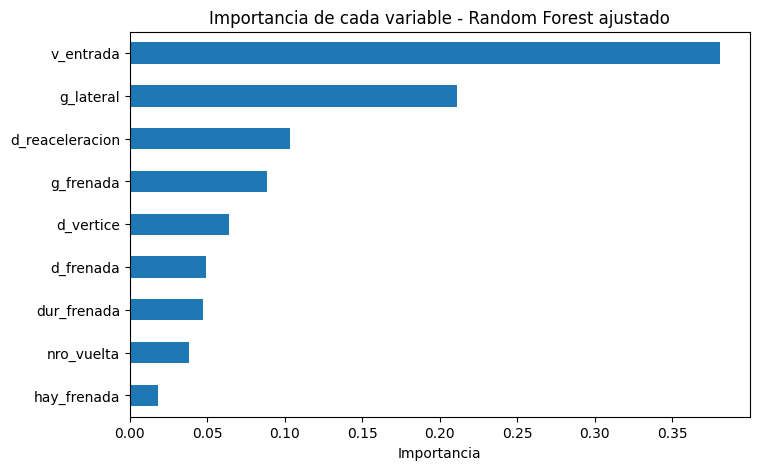

v_entrada          0.381
g_lateral          0.211
d_reaceleracion    0.103
g_frenada          0.088
d_vertice          0.064
d_frenada          0.049
dur_frenada        0.047
nro_vuelta         0.038
hay_frenada        0.018
dtype: float64


In [ ]:
importancias = pd.Series(modelRF_final.feature_importances_, index=variables).sort_values()   # cuánto pesa cada variable

importancias.plot(kind="barh", figsize=(8, 5))
plt.xlabel("Importancia")
plt.title("Importancia de cada variable - Random Forest ajustado")
plt.show()

print(importancias.sort_values(ascending=False).round(3))

###Factor principal en las tandas de testeo
Para cada tanda de testeo se comparan las pasadas que el modelo marcó como malas con las que marcó como buenas: se calcula el promedio de la pérdida y de las 3 variables más importantes en cada grupo, y se cuentan las curvas donde más se repiten las pasadas malas.

In [ ]:
resultado = test.copy() #Copiamos los resultados del modelo
resultado["tipo"] = predRF_final # lo que dijo el modelo
resultado["tipo"] = resultado.tipo.map({0: "buena", 1: "mala"})  # en palabras, para que se lea mejor

# Promedio de las 3 variables principales en pasadas buenas y malas de cada tanda
resultado.groupby(["tanda", "tipo"])[["perdida_ms", "v_entrada", "g_lateral", "d_vertice"]].mean().round(2)
#perdida_ms en ms
#v_entrada en Km/h
#g_lateral en g
#d_vertice en metros

perdida_ms  v_entrada  g_lateral  d_vertice
tanda tipo                                              
T17   buena       44.94      -0.21       0.01      -1.60
      mala       132.07      -2.14      -0.09       0.28
T18   buena       83.28      -0.37      -0.01       5.60
      mala       133.55      -1.95      -0.08      -1.94
T19   buena       31.41      -0.04      -0.00       0.11
      mala        75.71      -1.39      -0.06      -7.52
T21   buena      119.96      -0.36      -0.04       0.16
      mala       211.92      -2.45      -0.13      -3.51

In [ ]:
malas = resultado[resultado.tipo == "mala"] # solo las pasadas que el modelo marco como malas
malas.groupby("tanda").curva.value_counts().groupby("tanda").head(3).rename("cantidad pasadas malas") # las 3 curvas con mas pasadas malas en cada tanda

tanda  curva
T17    8        4
       9        3
       13       3
T18    2        5
       7        5
       8        5
T19    1        1
       2        1
       3        1
T21    8        8
       4        7
       7        7
Name: cantidad pasadas malas, dtype: int64

Lectura de las tablas (diferencias contra la referencia del piloto: `perdida_ms` en ms, `v_entrada` en km/h, `g_lateral` en g, `d_vertice` en metros)

- Tiempo perdido: en todas las tandas, las pasadas malas pierden más que las buenas de la misma tanda: T17 132,07 contra 44,94 ms, T18 133,55 contra 83,28 ms; T19 75,71 contra 31,41 ms; T21 211,92 contra 119,96 ms.
- Velocidad de entrada: las malas llegan entre 1,39 km/h (T19) y 2,45 km/h (T21) más lento que la referencia, en las buenas la diferencia es como máximo de 0,37 km/h (T18).
- Agarre lateral: las malas usan entre 0,06 g (T19) y 0,13 g (T21) menos que la referencia, en las buenas la diferencia está entre +0,01 y -0,04 g.
- Vértice: en T18, T19 y T21 las malas hacen el vértice antes que la referencia (1,94 m, 7,52 m y 3,51 m antes). En T18 se ve el contraste más claro: en las buenas el vértice está 5,60 m más tarde y en las malas, 1,94 m más temprano. En T17 no se da este patrón (+0,28 m).
- Curvas: la curva 8 aparece entre las tres con más pasadas malas en T17 (4), T18 (5) y T21 (8); la curva 7 en T18 (5) y T21 (7). En T19 las pasadas malas están repartidas, con una sola por curva.

Entonces las tandas nuevas, el factor principal es llegar lento a la curva y no aprovechar el agarre, presente en las cuatro tandas, seguido de hacer el vértice demasiado temprano, presente en tres.

La curva donde más se repite es la 8.

###Conclusiones

¿Las acciones del piloto permiten predecir si una pasada pierde tiempo?
Sí, de forma parcial. El Random Forest ajustado alcanza un 72 % de accuracy en tandas que nunca vio, detecta 2 de cada 3 pasadas malas (recall 0,68) y supera claramente tanto al azar como a responder siempre la clase mayoritaria. No llega a valores más altos porque, con el umbral en la mediana, muchas pasadas de cada lado son casi idénticas, y porque parte de la pérdida depende de información que no se registró (freno, acelerador, trayectoria, tráfico).

¿Qué factores explican la pérdida de tiempo?
Las variables más importantes son la velocidad de entrada (aproximadamente 38 %) y la aceleración lateral (aproximadamente 21 %). Mucho más atrás quedan la reaceleración, la frenada y el vértice. El punto de frenada, que suele ser lo primero que se mira en telemetría, pesa solo un 5 %. Esto indica que en Villaguay el tiempo se pierde principalmente por no llevar velocidad: salir lento de una curva (lo que se arrastra a la siguiente) y no aprovechar todo el agarre disponible en la curva.

¿Cuál es el factor que más se repite en una tanda nueva?
En las 4 tandas de testeo, de los 3 pilotos, las pasadas malas comparten el mismo patrón: llegan más lento a la curva y usan menos agarre lateral. En tres de las cuatro tandas, además, el vértice se hace antes de tiempo. La curva donde más se repite es la 8, presente en tres de las cuatro tandas.

Fortalezas
- Datos reales de telemetría, con detección del estado de pista a partir de los propios datos.
- Evaluación con separación por tandas. Las referencias y los umbrales se calcularon antes de dividir los datos, por lo que los resultados deben interpretarse como exploratorios.
- Resultado interpretable: además de predecir, el modelo permite explicar qué hace el piloto en las pasadas malas.

Limitaciones
- Dataset chico (949 pasadas, 17 tandas) y de un solo circuito.
- Sin sensores de freno ni de acelerador: la frenada y la reaceleración se infieren de la aceleración longitudinal.
- No se pudo usar la trayectoria por la baja precisión del GPS de uno de los pilotos.
- La etiqueta `pierde` es relativa (la mitad más lenta de cada curva), por lo que las pasadas cercanas a la mediana son difíciles de clasificar.
- La velocidad de entrada depende en gran parte de la curva anterior, por lo que señala dónde empieza el problema más que una acción dentro de la propia curva.

Posibles mejoras y líneas futuras
- Entrenar el modelo solo con pasadas claramente buenas o claramente malas (por ejemplo, el tercio más rápido y el tercio más lento de cada curva), descartando las intermedias, que son casi idénticas entre sí y concentran la mayor parte de los errores del modelo.
- Sumar más tandas y otros circuitos.
- Incorporar sensores de freno y acelerador, y la trayectoria con un GPS más preciso.
- Incorporar la marcha utilizada en cada curva (calculada a partir de RPM y velocidad).
- Entrenar un modelo específico para pista mojada, o agregar el estado de pista como variable.
- Relacionar cada pasada con la salida de la curva anterior, para separar mejor "llegó lento" de "lo hizo mal en esta curva".
- Comparar el diagnóstico del modelo con un análisis basado en reglas definidas por un experto.

## Archivos del trabajo y fuentes

`datos_villaguay.zip`, Los 21 archivos de telemetría originales (CSV exportados de AiM Race Studio 3), anonimizados

`anexo_construccion_dataset.py` Script en Python que lee los 21 CSV, los corta en vueltas y mide cada una de las 13 curvas (tiempo del tramo, velocidad de entrada, vértice, frenada, reaceleración y aceleración lateral). Genera el dataset usado en el notebook.

`pasadas_villaguay.csv` Dataset resultante: una fila por pasada (vuelta * curva), 1.261 filas antes del filtrado. Es el archivo que se carga en la sección 2.

Los datos pertenecen a tandas reales de 3 pilotos en el circuito de Villaguay (Entre Ríos), registradas entre el 14 y el 16 de agosto de 2026 con dataloggers AiM MyChron.

### Fuentes

Datos y herramientas de adquisición
- AiM MyChron y Race Studio 3 (exportación CSV): https://www.aim-sportline.com

Librerías
- pandas: https://pandas.pydata.org/docs/
- matplotlib: https://matplotlib.org/stable/
- scikit-learn: https://scikit-learn.org/stable/

Modelos (scikit-learn)
- DecisionTreeClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- RandomForestClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- GradientBoostingClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html
- Módulo de ensambles: https://scikit-learn.org/stable/api/sklearn.ensemble.html

Validación y ajuste de hiperparámetros
- GridSearchCV: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html
- GroupKFold: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html

Métricas
- accuracy_score: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.accuracy_score.html
- classification_report: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html
- confusion_matrix: https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html